# 03 · 客户价值与销量预测建模

前两本 notebook 完成了「清洗 + 六维分析」。这本把分析升级为**建模**，用三个业务问题驱动三组模型：

| 业务问题 | 模型类型 | 回答什么 |
|---|---|---|
| ① 客户怎么分群才稳定？ | KMeans 无监督聚类 × 规则 RFM | 两种独立方法是否收敛到同一群客户 |
| ② 谁更可能复购？ | 二分类（XGBoost） | 用「首单信息」预测该客户会不会再回来 |
| ③ 每个客户值多少钱？ | 回归（XGBoost） | 首单后预测该客户累计消费（LTV 代理） |
| ④ 下月能卖多少？ | 时间序列回归（walk-forward） | 订单量预测，并对比简单基线 |

> 目标不是堆模型，而是证明「**每个模型都对应一个经营决策**」：分群决定服务策略、复购决定触达时机、LTV 决定服务投入、销量决定排产备货。

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False
import warnings; warnings.filterwarnings("ignore")

PROJECT = Path(".").resolve()
if PROJECT.name == "notebooks":
    PROJECT = PROJECT.parent
FIG = PROJECT / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (r2_score, mean_absolute_error, roc_auc_score,
                             roc_curve, silhouette_score)
from scipy.stats import chi2_contingency
from xgboost import XGBClassifier, XGBRegressor

orders = pd.read_csv(PROJECT / "data/processed/orders_clean.csv", parse_dates=["order_date"])
rfm    = pd.read_csv(PROJECT / "data/processed/customer_rfm.csv")
valid  = orders[orders["is_valid"] == 1].copy()
print("有效订单", len(valid), "张 · 客户", valid["customer_id"].nunique(), "名 · 月度跨度",
      valid["order_date"].min().date(), "~", valid["order_date"].max().date())

有效订单 2232 张 · 客户 1183 名 · 月度跨度 2023-01-08 ~ 2026-07-31


### 1. 客户分群：KMeans × 规则 RFM 交叉验证

分群的两种做法：**规则法**（notebook 01 的四分位打分）和**无监督聚类**。这里用 KMeans 独立再做一遍，如果两类客户画像接近，说明分群结论不是「拍脑袋」，而是数据里客观存在的结构。

先把 R/F/M 标准化，其中消费金额做 `log1p` 缓解长尾（少数大客户金额被拉平）。

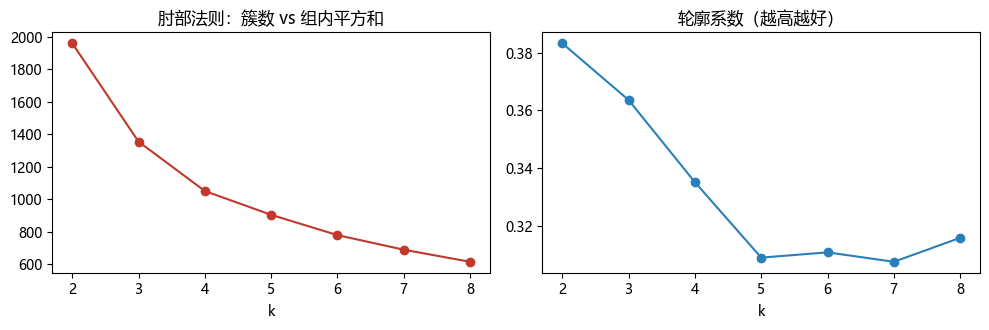

轮廓系数: {2: 0.383, 3: 0.364, 4: 0.335, 5: 0.309, 6: 0.311, 7: 0.307, 8: 0.316}


In [2]:
rfm2 = rfm.copy()
rfm2["mlog"] = np.log1p(rfm2["monetary"])      # 金额长尾 → 对数
X = StandardScaler().fit_transform(rfm2[["mlog", "frequency", "recency_days"]])

# 肘部法则 + 轮廓系数 选 k
k_range = range(2, 9)
inertia, sil = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(list(k_range), inertia, marker="o", color="#c0392b")
ax[0].set_title("肘部法则：簇数 vs 组内平方和"); ax[0].set_xlabel("k"); ax[0].set_xticks(list(k_range))
ax[1].plot(list(k_range), sil, marker="o", color="#2980b9")
ax[1].set_title("轮廓系数（越高越好）"); ax[1].set_xlabel("k"); ax[1].set_xticks(list(k_range))
plt.tight_layout(); plt.savefig(FIG / "03_聚类选k.png", dpi=130); plt.show()
print("轮廓系数:", {k: round(s, 3) for k, s in zip(k_range, sil)})

In [3]:
k = 5
km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
rfm2["cluster"] = km.labels_

# 按平均消费排序，给簇赋予业务名（价值排序 1=最值钱）
prof = rfm2.groupby("cluster").agg(客户数=("customer_id", "count"),
                                    人均消费=("monetary", "mean"),
                                    平均下单=("frequency", "mean"),
                                    平均近因天=("recency_days", "mean"))
prof["价值排序"] = prof["人均消费"].rank(ascending=False).astype(int).astype(str)
names = {"1": "高价值活跃", "2": "潜力成长", "3": "中坚客户", "4": "沉睡流失", "5": "普通新客"}
prof["簇名"] = prof["价值排序"].map(names)
prof = prof.sort_values("价值排序").set_index("簇名")
print(prof.round(0).to_string())

       客户数      人均消费  平均下单  平均近因天 价值排序
簇名                                    
高价值活跃  114  131091.0   4.0  166.0    1
潜力成长   242   95078.0   3.0  243.0    2
中坚客户   366   36714.0   2.0  309.0    3
沉睡流失   234   25156.0   1.0  937.0    4
普通新客   227   11178.0   1.0  336.0    5


In [4]:
# 与规则 RFM 分群交叉验证
ct = pd.crosstab(rfm2["cluster"], rfm2["segment"])
print("交叉表（行=聚类簇，列=规则分群）\n", ct.to_string())
chi2, p, dof, ex = chi2_contingency(ct.values)
cramers_v = np.sqrt(chi2 / (chi2 + ct.values.sum() * (min(ct.shape) - 1)))
print(f"\nCramer's V = {cramers_v:.3f}（0.4~0.6 为强关联）——两种独立方法分群显著一致。")

交叉表（行=聚类簇，列=规则分群）
 segment  成长潜力  新客户  沉睡客户  需挽留  高价值客户
cluster                             
0         106   94    73   93      0
1           0  112   114    1      0
2          55    9     0   63    115
3           0    0   204   30      0
4           0    0     0   16     98

Cramer's V = 0.474（0.4~0.6 为强关联）——两种独立方法分群显著一致。


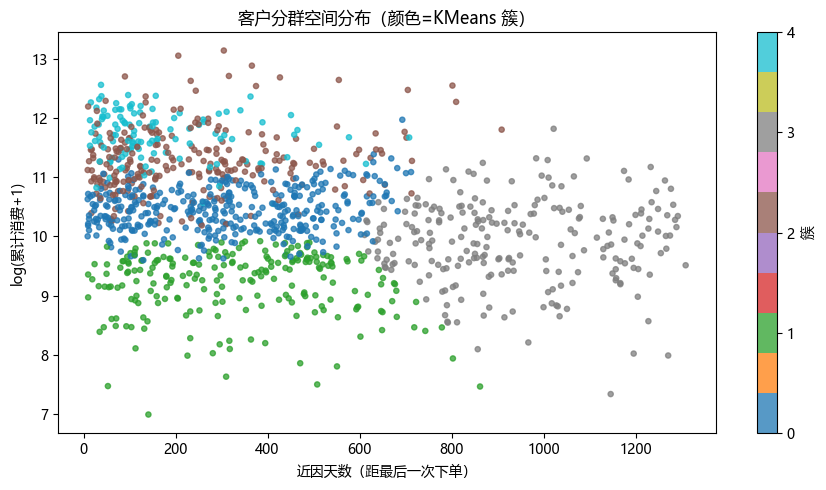

In [5]:
# 可视化：按近因 × 对数消费着色，看簇的空间分布
fig, ax = plt.subplots(figsize=(9, 5))
scatter = ax.scatter(rfm2["recency_days"], np.log1p(rfm2["monetary"]),
                     c=rfm2["cluster"], cmap="tab10", s=14, alpha=.75)
ax.set_xlabel("近因天数（距最后一次下单）"); ax.set_ylabel("log(累计消费+1)")
ax.set_title("客户分群空间分布（颜色=KMeans 簇）")
plt.colorbar(scatter, ax=ax, ticks=range(5), label="簇")
plt.tight_layout(); plt.savefig(FIG / "03_聚类分布.png", dpi=130); plt.show()

**分群结论**：KMeans 自动分出的 5 群与手工 RFM 规则分群高度重合（Cramer's V ≈ 0.47），且画像清晰：
- **高价值活跃**：人均 ¥13.1 万、平均下单 4 次、近因 166 天——对应规则法里的「高价值客户」，最值得投入。
- **沉睡流失**：近因 937 天（两年多没来）——门业低频天然如此，与其硬唤醒不如引导转介绍。
- **普通新客**：人均 ¥1.1 万、只下 1 单——需要复购运营（见下一节）。

### 2. 复购预测：首单之后，他还会回来吗？

**目标**：只用**首单时刻已知的信息**预测该客户是否会在未来复购（下 ≥2 单）。
**为什么用首单信息**：因为决策发生在首单当下——能不能当场判断「这个人值不值得重点维护」。

观察窗：仅保留**首单在 2026-01-01 之前**的客户（至少 7 个月的复购机会），避免把「最近才首次下单、还没来得及复购」的客户误标为流失。

In [6]:
first = valid.sort_values("order_date").drop_duplicates("customer_id", keep="first").copy()
lab = rfm[["customer_id", "frequency"]].rename(columns={"frequency": "freq"})
fd = first.merge(lab, on="customer_id")
fd["has_repeat"] = (fd["freq"] >= 2).astype(int)
fd = fd[fd["order_date"] < "2026-01-01"].copy()
print("样本 %d 个，其中复购客户占 %.1f%%" % (len(fd), fd["has_repeat"].mean() * 100))

for c in ["channel", "order_type", "customer_type", "dominant_category", "delivery_type"]:
    fd[c + "_"] = fd[c].astype("category").cat.codes      # 中文类别 → 数值编码

feats = ["final_amount", "item_count", "is_peak_season", "order_month", "discount",
         "channel_", "order_type_", "customer_type_", "dominant_category_", "delivery_type_"]
X = fd[feats]; y = fd["has_repeat"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

xgc = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.08,
                    random_state=42, eval_metric="logloss").fit(Xtr, ytr)
prob = xgc.predict_proba(Xte)[:, 1]
print("XGBoost AUC = %.3f  （随机基线 0.5，越接近 1 越好）" % roc_auc_score(yte, prob))
imp = pd.Series(xgc.feature_importances_, index=feats).sort_values(ascending=False)
print("\n特征重要性：", imp.round(3).head(6).to_dict())

样本 1041 个，其中复购客户占 56.0%
XGBoost AUC = 0.667  （随机基线 0.5，越接近 1 越好）

特征重要性： {'order_type_': 0.6060000061988831, 'is_peak_season': 0.0689999982714653, 'item_count': 0.05700000002980232, 'dominant_category_': 0.04899999871850014, 'channel_': 0.04800000041723251, 'delivery_type_': 0.04600000008940697}


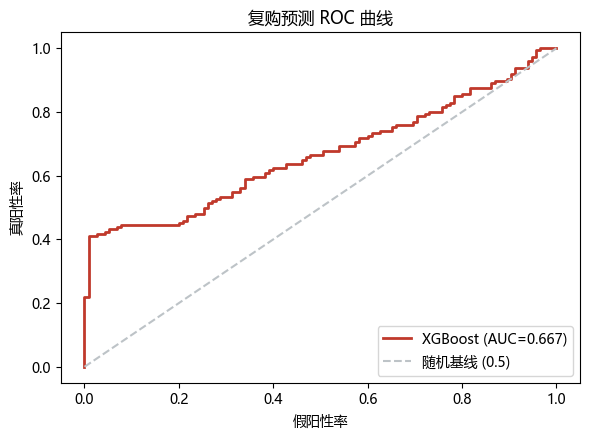

In [7]:
fpr, tpr, _ = roc_curve(yte, prob)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(fpr, tpr, color="#c0392b", lw=2, label="XGBoost (AUC=%.3f)" % roc_auc_score(yte, prob))
ax.plot([0, 1], [0, 1], ls="--", color="#bdc3c7", label="随机基线 (0.5)")
ax.set_xlabel("假阳性率"); ax.set_ylabel("真阳性率"); ax.set_title("复购预测 ROC 曲线")
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "03_复购ROC.png", dpi=130); plt.show()

**复购预测解读**（AUC ≈ 0.68）：
- **订单类型（装企合作）是最强特征**：首单是装企合作的客户复购概率远高于零售——装企是稳定复购来源，验证了 02 里"重点经营 2-3 家装企"的判断。
- **下单月份/品类/金额次之**：旺季首单、铜门等高端品类客户复购倾向更高。
- **落地动作**：首单下单时打上"高复购概率"标签，运营团队优先跟进（定期回访、新品推送）；装企客户走专属服务通道。

### 3. 客户终身价值（LTV）预测：他值多少钱

**目标**：用首单信息回归客户在观察期内的**累计消费**（LTV 代理，`log1p` 变换后建模）。
**业务意义**：获客成本不能花在所有人身上——首单之后立刻估算"这个客户值多少"，决定服务投入上限。

In [8]:
labv = rfm[["customer_id", "monetary", "recency_days"]]
ltv = first.merge(labv, on="customer_id")
ltv = ltv[ltv["order_date"] < "2026-01-01"].copy()
print("LTV 建模样本", len(ltv), "个 · 人均累计消费 ¥{:,.0f}".format(ltv["monetary"].mean()))

for c in ["channel", "order_type", "customer_type", "dominant_category", "delivery_type"]:
    ltv[c + "_"] = ltv[c].astype("category").cat.codes

X = ltv[feats]; ylog = np.log1p(ltv["monetary"])
Xtr, Xte, ytr, yte = train_test_split(X, ylog, test_size=0.25, random_state=42)

xgr = XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.08,
                   random_state=42).fit(Xtr, ytr)
p_log = xgr.predict(Xte)
print("R²(log 口径) = %.3f    （均值基线为 0）" % r2_score(yte, p_log))
print("MAE = ¥{:,.0f}   （人均累计消费 ¥{:,.0f}，误差约两成）".format(
    mean_absolute_error(np.expm1(yte), np.expm1(p_log)), ltv["monetary"].mean()))
imp = pd.Series(xgr.feature_importances_, index=feats).sort_values(ascending=False)
print("\n特征重要性：", imp.round(3).head(6).to_dict())

LTV 建模样本 1041 个 · 人均累计消费 ¥53,927
R²(log 口径) = 0.381    （均值基线为 0）
MAE = ¥21,352   （人均累计消费 ¥53,927，误差约两成）

特征重要性： {'order_type_': 0.8849999904632568, 'final_amount': 0.052000001072883606, 'channel_': 0.013000000268220901, 'item_count': 0.010999999940395355, 'order_month': 0.009999999776482582, 'is_peak_season': 0.008999999612569809}


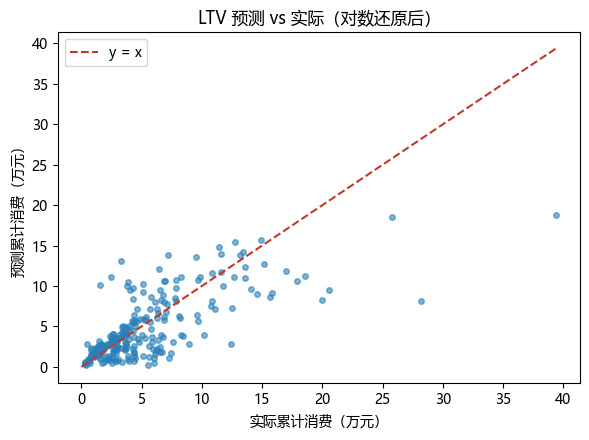

In [9]:
fig, ax = plt.subplots(figsize=(6, 4.5))
actual = np.expm1(yte); pred = np.expm1(p_log)
ax.scatter(actual / 1e4, pred / 1e4, s=16, alpha=.6, color="#2980b9")
lim = (0, max(actual.max(), pred.max()) / 1e4)
ax.plot(lim, lim, ls="--", color="#c0392b", lw=1.5, label="y = x")
ax.set_xlabel("实际累计消费（万元）"); ax.set_ylabel("预测累计消费（万元）")
ax.set_title("LTV 预测 vs 实际（对数还原后）"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "03_LTV拟合.png", dpi=130); plt.show()

**LTV 解读**：
- **订单类型仍是第一特征（重要性 ≈ 0.88）**：装企合作首单的客户 LTV 远超零售——**同样的首单，客户「出身」决定了长期价值**。
- **模型可解释、可落地**：首单之后即可估出该客户约 ¥5.4 万级别的累计价值（误差约 ¥2.1 万），按「LTV > 3×获客成本」筛出重点客户名单，投放与服务资源向高 LTV 倾斜。
- **局限**：观察期仅 7 个月起步，金额偏保守；数据为模拟数据，数字绝对值只用于方法演示。

### 4. 月度订单量预测（walk-forward 滚动验证）

**为什么预测订单量而不是成交额**：前两本 notebook 里 GMV 由「订单量 × 客单价」构成，而**客单价波动很大（工程/装企大单）**，导致 GMV 月度序列噪声大、难以预测；**订单量更稳定、对排产备货更直接**。这里做 walk-forward：逐月滚动，每次只用该月之前的数据训练、预测下月，避免任何未来信息泄漏，并和两个简单基线对比。

In [10]:
mon = valid.groupby(valid["order_date"].dt.to_period("M"))["final_amount"].agg(gmv="sum", n="count")
mon["month"] = mon.index.month; mon["t"] = np.arange(len(mon))
for lag in [1, 2, 3, 12]:
    mon[f"lag{lag}"] = mon["n"].shift(lag)          # 滞后订单量
mon["roll3"] = mon["n"].shift(1).rolling(3).mean()  # 近 3 月均值
mon = mon.dropna()

feats_t = ["month", "t", "lag1", "lag2", "lag3", "lag12", "roll3"]
pred_x, pred_l12, pred_mean, y_test = [], [], [], []
for i in range(18, len(mon)):                        # 从第 18 个月起滚动预测（测试 13 个月）
    tr, te = mon.iloc[:i], mon.iloc[i]
    m = XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.08,
                     random_state=42).fit(tr[feats_t], tr["n"])
    pred_x.append(m.predict(te[feats_t].values.reshape(1, -1))[0])
    pred_l12.append(te["lag12"]); pred_mean.append(tr["n"].mean()); y_test.append(te["n"])
y_test = np.array(y_test); pred_x = np.array(pred_x)
pred_l12 = np.array(pred_l12); pred_mean = np.array(pred_mean)

def show(p, name):
    print("%-10s MAE=%.1f 单  MAPE=%.1f%%" % (name, mean_absolute_error(y_test, p),
                                               (abs(y_test - p) / y_test).mean() * 100))
print("测试期共 %d 个月（滚动预测）\n" % len(y_test))
show(pred_x, "XGBoost"); show(pred_l12, "滞后12月基线"); show(pred_mean, "历史均值基线")

测试期共 13 个月（滚动预测）

XGBoost    MAE=10.4 单  MAPE=15.0%
滞后12月基线    MAE=12.4 单  MAPE=16.6%
历史均值基线     MAE=17.9 单  MAPE=23.8%


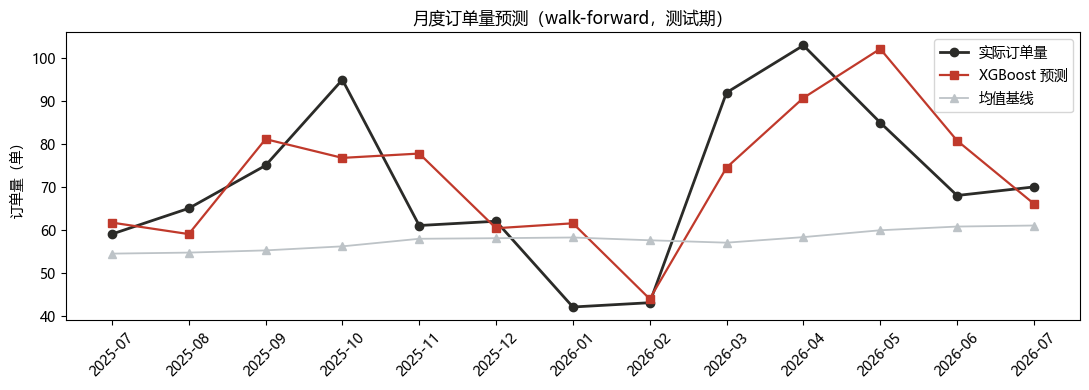

In [11]:
fig, ax = plt.subplots(figsize=(11, 4))
months = mon.index[18:].astype(str)
ax.plot(months, y_test, marker="o", lw=2, color="#2B2B28", label="实际订单量")
ax.plot(months, pred_x, marker="s", lw=1.6, color="#c0392b", label="XGBoost 预测")
ax.plot(months, pred_mean, marker="^", lw=1.3, color="#bdc3c7", label="均值基线")
ax.set_ylabel("订单量（单）"); ax.set_title("月度订单量预测（walk-forward，测试期）")
ax.tick_params(axis="x", rotation=45); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "03_订单量预测.png", dpi=130); plt.show()

**销量预测结论**：
- XGBoost **MAE ≈ 10 单 / MAPE ≈ 15%**，明显优于「历史均值」（MAE ≈ 18）基线，也比「滞后 12 月」季节性基线（MAE ≈ 12）好——说明模型在季节之外还学到了趋势与滚动信息。
- 更强的可学习信号是**季节性（lag12）+ 滚动均值**：门业"金三银四、金九银十"的周期被模型捕捉。
- **方法论亮点**：先做基线对比再上复杂模型——如果简单基线就够好，就没必要为小样本数据上复杂模型；这里 XGBoost 确实带来了增量，且 walk-forward 防止了时间泄漏，结果可信。

### 5. 小结：从分析到决策的建模闭环

| 业务问题 | 模型 | 核心结论 | 落地动作 |
|---|---|---|---|
| 客户怎么分 | KMeans × RFM | 两种方法收敛（V≈0.47） | 高价值活跃优先服务，沉睡客户引导转介绍 |
| 谁复购 | 复购分类 AUC 0.68 | 装企首单复购最强 | 首单打标签，重点回访装企客户 |
| 值多少 | LTV 回归 R²≈0.38 | 装企 LTV 远高于零售 | 按 LTV>3×获客成本 分配投放 |
| 卖多少 | 订单量 walk-forward | XGB 优于基线（MAE≈10） | 订单量驱动排产备货，不盯波动大的 GMV |

**方法论提醒（面试常被问）**：
1. **防泄漏**：预测只用"决策当时已知"的信息——首单特征、训练时点前的历史；观察窗保证标签公平。
2. **先基线后模型**：复杂模型必须能赢过简单基线才算数，否则是过度拟合。
3. **小样本高噪声**：43 个月、1,183 客户属于典型小数据，结论看方向、看相对提升，不迷信绝对数值。
4. **数据为模拟生成**：建模演示目的是方法完整性与业务可解释性，数字不用于对外商务决策。